# Lab 9 : Polynomial Regression
**Lakshay** : AP24110010677 : B.Tech CSE (AI/ML)

**Question** (from the Unit 1 slides) : The number of hours studied and the grade points are given for a few samples. **Fit a 2nd-order polynomial** for all the given data points.

| X (hours) | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|---|---|---|---|---|---|---|---|---|---|
| Y (grade points) | 57 | 66 | 73 | 76 | 79 | 81 | 90 | 96 | 100 |

Solved **two ways** : (1) calculation using the normal equations; (2) a program (NumPy / scikit-learn). The curve is also compared with a straight line.

## What is Polynomial Regression?
When the data follows a **curve** instead of a straight line, we model $y$ as an $m$-th degree polynomial in $x$:

$$y = \beta_0 + \beta_1 x + \beta_2 x^2 + \dots + \beta_m x^m + \epsilon$$

For **2nd order** (degree 2) : $\;\hat y = \beta_0 + \beta_1 x + \beta_2 x^2$ (a parabola).

**Why is it still "linear" regression?** The curve is non-linear in $x$, but the model is **linear in the unknown parameters** $\beta$. If we treat $x$ and $x^2$ as two separate features, it becomes **multiple linear regression**, so the same formula works:

$$X = \begin{bmatrix}1 & x_1 & x_1^2\\ 1 & x_2 & x_2^2\\ \vdots&\vdots&\vdots\\ 1 & x_n & x_n^2\end{bmatrix}, \qquad \beta = (X^TX)^{-1}X^Ty$$

Written out, $X^TX\beta = X^Ty$ gives the three **normal equations** used in hand calculation:

$$\begin{aligned}
\textstyle\sum y &= n\beta_0 + \beta_1\sum x + \beta_2\sum x^2\\
\textstyle\sum xy &= \beta_0\sum x + \beta_1\sum x^2 + \beta_2\sum x^3\\
\textstyle\sum x^2y &= \beta_0\sum x^2 + \beta_1\sum x^3 + \beta_2\sum x^4
\end{aligned}$$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

np.set_printoptions(suppress=True)
np.random.seed(77)            # last two digits of roll number

## Dataset

In [2]:
x = np.array([2, 3, 4, 5, 6, 7, 8, 9, 10])
y = np.array([57, 66, 73, 76, 79, 81, 90, 96, 100])
n = len(x)
pd.DataFrame({"x (hours)": x, "y (grade points)": y})

,x (hours),y (grade points)
0,2,57
1,3,66
2,4,73
3,5,76
4,6,79
5,7,81
6,8,90
7,9,96
8,10,100


---
## Part 1 : Calculation (normal equations)
### Step 1 : table of powers and products

In [3]:
t = pd.DataFrame({"x": x, "y": y, "x²": x**2, "x³": x**3, "x⁴": x**4,
                  "xy": x*y, "x²y": x**2 * y})
t.loc["Σ"] = t.sum()
print(t.to_string())

    x    y   x²    x³     x⁴    xy    x²y
0   2   57    4     8     16   114    228
1   3   66    9    27     81   198    594
2   4   73   16    64    256   292   1168
3   5   76   25   125    625   380   1900
4   6   79   36   216   1296   474   2844
5   7   81   49   343   2401   567   3969
6   8   90   64   512   4096   720   5760
7   9   96   81   729   6561   864   7776
8  10  100  100  1000  10000  1000  10000
Σ  54  718  384  3024  25332  4609  34239


### Step 2 : write the three normal equations

In [4]:
S = t.loc["Σ"]
print(f"{S['y']:>6} = {n}β₀ + {S['x']}β₁ + {S['x²']}β₂")
print(f"{S['xy']:>6} = {S['x']}β₀ + {S['x²']}β₁ + {S['x³']}β₂")
print(f"{S['x²y']:>6} = {S['x²']}β₀ + {S['x³']}β₁ + {S['x⁴']}β₂")

   718 = 9β₀ + 54β₁ + 384β₂
  4609 = 54β₀ + 384β₁ + 3024β₂
 34239 = 384β₀ + 3024β₁ + 25332β₂


### Step 3 : solve the 3×3 system  ( same as $\beta = (X^TX)^{-1}X^Ty$ )

In [5]:
A = np.array([[n,       S["x"],  S["x²"]],
              [S["x"],  S["x²"], S["x³"]],
              [S["x²"], S["x³"], S["x⁴"]]], dtype=float)     # this is XᵀX
B = np.array([S["y"], S["xy"], S["x²y"]], dtype=float)       # this is Xᵀy

b0, b1, b2 = np.linalg.solve(A, B)
print("XᵀX =\n", A, "\n\nXᵀy =", B)
print(f"\nβ₀ = {b0:.4f}\nβ₁ = {b1:.4f}\nβ₂ = {b2:.4f}")
print(f"\nFitted 2nd-order polynomial :  ŷ = {b0:.4f} + {b1:.4f}·x + ({b2:.4f})·x²")

XᵀX =
 [[    9.    54.   384.]
 [   54.   384.  3024.]
 [  384.  3024. 25332.]] 

Xᵀy = [  718.  4609. 34239.]

β₀ = 48.9476
β₁ = 5.3154
β₂ = -0.0249

Fitted 2nd-order polynomial :  ŷ = 48.9476 + 5.3154·x + (-0.0249)·x²


### Step 4 : check using the design-matrix formula directly

In [6]:
X = np.column_stack([np.ones(n), x, x**2])
beta = np.linalg.inv(X.T @ X) @ X.T @ y
print("Design matrix X (first 3 rows):\n", X[:3])
print("\nβ = (XᵀX)⁻¹Xᵀy =", beta.round(4))

Design matrix X (first 3 rows):
 [[ 1.  2.  4.]
 [ 1.  3.  9.]
 [ 1.  4. 16.]]

β = (XᵀX)⁻¹Xᵀy = [48.9476  5.3154 -0.0249]


---
## Part 2 : Program
`PolynomialFeatures(degree=2)` turns $x$ into $[1, x, x^2]$, then ordinary `LinearRegression` fits it. `np.polyfit` is a one-line alternative.

In [7]:
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(x.reshape(-1, 1))        # columns : x, x²

model = LinearRegression().fit(X_poly, y)
print(f"sklearn  : β₀ = {model.intercept_:.4f}, β₁ = {model.coef_[0]:.4f}, β₂ = {model.coef_[1]:.4f}")

c2, c1, c0 = np.polyfit(x, y, 2)                     # highest power first
print(f"polyfit  : β₀ = {c0:.4f}, β₁ = {c1:.4f}, β₂ = {c2:.4f}")
print(f"by hand  : β₀ = {b0:.4f}, β₁ = {b1:.4f}, β₂ = {b2:.4f}")

sklearn  : β₀ = 48.9476, β₁ = 5.3154, β₂ = -0.0249
polyfit  : β₀ = 48.9476, β₁ = 5.3154, β₂ = -0.0249
by hand  : β₀ = 48.9476, β₁ = 5.3154, β₂ = -0.0249


In [8]:
h = 11
print(f"Predicted grade points for {h} hours = {model.predict(poly.transform([[h]]))[0]:.2f}")

Predicted grade points for 11 hours = 104.40


---
## Evaluation & comparison with a straight line
### Theory : how good is the model?
* **R² (coefficient of determination)** : what fraction of the variation in $y$ the model explains. Closer to **1** is better.
$$R^2 = 1 - \frac{SSE}{SST} = \frac{SSR}{SST}, \quad SSE=\sum(y_i-\hat y_i)^2,\; SST=\sum(y_i-\bar y)^2,\; SSR=\sum(\hat y_i-\bar y)^2$$
* **RMSE** : $\sqrt{\frac{1}{n}\sum(y_i-\hat y_i)^2}$ : average size of the error, in the same unit as $y$. Lower is better.
* **MAE** : $\frac{1}{n}\sum|y_i-\hat y_i|$ : average absolute error. Lower is better.

In [9]:
y_poly = model.predict(X_poly)
lin = LinearRegression().fit(x.reshape(-1, 1), y)
y_lin = lin.predict(x.reshape(-1, 1))

def metrics(y, y_hat):
    SSE = ((y - y_hat) ** 2).sum(); SST = ((y - y.mean()) ** 2).sum()
    return 1 - SSE/SST, np.sqrt(SSE/len(y)), np.abs(y - y_hat).mean()

res = pd.DataFrame([metrics(y, y_lin), metrics(y, y_poly)],
                   index=["Linear (degree 1)", "Polynomial (degree 2)"],
                   columns=["R²", "RMSE", "MAE"]).round(4)
print(res)
print(f"\nsklearn check (degree 2) : R² = {r2_score(y, y_poly):.4f}")

                           R²    RMSE     MAE
Linear (degree 1)      0.9757  2.0423  1.6185
Polynomial (degree 2)  0.9759  2.0371  1.6351

sklearn check (degree 2) : R² = 0.9759


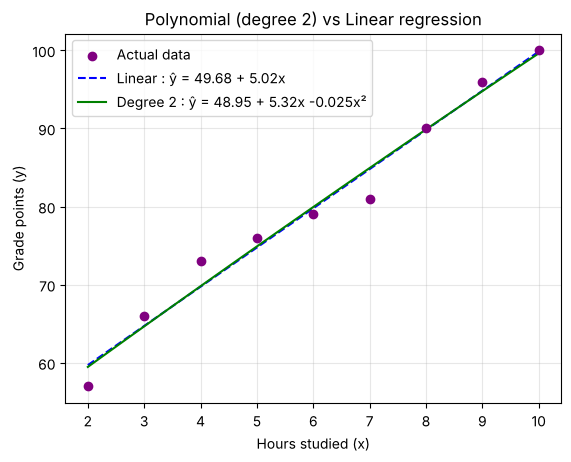

In [10]:
xs = np.linspace(2, 10, 100)
plt.scatter(x, y, color="purple", zorder=3, label="Actual data")
plt.plot(xs, lin.predict(xs.reshape(-1, 1)), "b--",
         label=f"Linear : ŷ = {lin.intercept_:.2f} + {lin.coef_[0]:.2f}x")
plt.plot(xs, model.predict(poly.transform(xs.reshape(-1, 1))), "g",
         label=f"Degree 2 : ŷ = {b0:.2f} + {b1:.2f}x {b2:+.3f}x²")
plt.xlabel("Hours studied (x)"); plt.ylabel("Grade points (y)")
plt.title("Polynomial (degree 2) vs Linear regression")
plt.legend(); plt.grid(alpha=0.3); plt.show()

## Conclusion
* By hand (normal equations), by matrix formula, by scikit-learn and by `np.polyfit`, the fitted curve is the **same**: $\hat y \approx 48.95 + 5.32x - 0.025x^2$.
* The small negative $x^2$ coefficient means the curve **bends very slightly downward** : extra hours still help, but a tiny bit less each time. Predicted grade for 11 hours ≈ **104.4**.
* For this data the degree-2 curve fits only slightly better than a straight line (R² 0.9759 vs 0.9757). The relationship is nearly linear, so the curved model adds little here.
* Polynomial regression is useful when a scatter plot shows a clear curve; too high a degree can **overfit** (pass through every point but predict badly on new data).